## **Проектная работа №1: Классификация объектов на изображении**









### **Цель:**


Разработать программу на Python, которая принимает на вход фотографию с изображением монет и вычисляет общую сумму денежных средств, отображенных на ней, используя только библиотеку OpenCV и стандартные библиотеки Python.


### **Базовая реализация:**



1. **Сбор изображения:**
   - Используйте камеру или загрузите готовое изображение с монетами для обработки.

2. **Предварительная обработка изображения:**
   - Преобразуйте изображение в оттенки серого.
   - Примените размытие Гаусса для уменьшения шума.
   - Используйте оператор Кэнни для обнаружения краев.

3. **Обнаружение кругов (монет):**
   - Используйте преобразование Хафа для обнаружения кругов на изображении.
   - Получите координаты центров и радиусов обнаруженных кругов (монет).

4. **Классификация монет:**
   - Определите номинал каждой монеты на основе ее радиуса.
   - Установите пороговые значения для радиусов, соответствующие разным номиналам:
     - **Маленький радиус:** 1 рубль.
     - **Средний радиус:** 2 рубля.
     - **Большой радиус:** 5 рублей.

5. **Подсчет общей суммы:**
   - Суммируйте номиналы всех обнаруженных монет.
   - Отобразите общую сумму на изображении или в консоли.

6. **Отображение результатов:**
   - Нарисуйте окружности на изображении вокруг обнаруженных монет.
   - Подпишите рядом с каждой монетой ее номинал.
   - Покажите исходное изображение с отмеченными монетами.
   - Выведите обработанные этапы для визуализации процесса (например, изображение после предварительной обработки, с контурами и т.д.).



### **Требования к реализации:**



- Использовать только библиотеку **OpenCV** и стандартные библиотеки Python (например, **NumPy**).
- Код должен быть хорошо документирован с комментариями для каждого основного блока.
- Предусмотреть возможность настройки параметров обработки через трекбары или отдельные переменные.



### **Рекомендации:**




- **Преобразование Хафа** для кругов является удобным инструментом для обнаружения круглых объектов на изображении.
- **Пороговые значения радиусов** необходимо подобрать экспериментально, протестировав на образцах монет разных номиналов.
- **Обработка перекрывающихся монет** может потребовать более сложных алгоритмов, таких как водоразделение или использование градиентных признаков.
- Тестируйте программу на различных изображениях с разным количеством и расположением монет, а также при разном освещении.





### **Ожидаемый результат:**




В результате выполнения задания вы получите программу, которая способна:

- Принимать на вход изображение с монетами.
- Обрабатывать изображение и обнаруживать монеты без использования библиотеки cvzone.
- Определять номинал каждой монеты на основе ее радиуса или других признаков.
- Вычислять и отображать общую сумму монет на изображении.



---

**Пример использования программы:**

- Пользователь запускает программу.
- Загружается изображение с монетами.
- Программа обрабатывает изображение, отмечает каждую монету и подписывает ее номинал.
- Отображается изображение с результатами и выводится общая сумма, например: **"Общая сумма: 37 рублей"**.



---

**Заметка:**

Данный проект позволит вам:

- Изучить и применить технологии обработки изображений с помощью OpenCV без привлечения сторонних библиотек.
- Научиться решать практические задачи компьютерного зрения, применяя базовые методы и улучшая их по мере необходимости.




---

**Советы по реализации:**

- **Настройка параметров:**
  - Для преобразования Хафа используйте функцию `cv2.HoughCircles()`.
  - Экспериментируйте с параметрами `dp`, `minDist`, `param1`, `param2`, `minRadius`, `maxRadius`.
- **Отображение результатов:**
  - Используйте функцию `cv2.circle()` для рисования окружностей.
  - Для отображения текста воспользуйтесь `cv2.putText()`.
- **Обработка ошибок:**
  - Обрабатывайте случаи, когда преобразование Хафа не обнаруживает ни одной монеты.
  - Предусмотрите проверку входных данных и вывод информативных сообщений для пользователя.

In [1]:
from urllib.request import Request, urlopen
import cv2
import numpy as np
from IPython.display import Image, display


def load_image(source):
    # Загрузка фотографии по ссылке или из файла.
    try:
        if source.startswith(('https://', 'http://')):
            request = Request(source, headers={'User-Agent': 'Mozilla/5.0'})
            with urlopen(request, timeout=30) as response:
                data = np.frombuffer(response.read(), dtype=np.uint8)
            image = cv2.imdecode(data, cv2.IMREAD_COLOR)
        else:
            image = cv2.imread(source)
    except (OSError, cv2.error):
        print('Не удалось загрузить изображение.')
        return None

    if image is None:
        print('Не удалось открыть изображение.')
    return image


def show_image(image, title, extension='.jpg'):
    # Показ изображения в ноутбуке.
    print(title)
    height, width = image.shape[:2]
    if width > 900:
        image = cv2.resize(image, (900, round(height * 900 / width)))
    success, buffer = cv2.imencode(extension, image)
    if success:
        display(Image(data=buffer.tobytes()))

In [2]:
# Размытие и границы.
blur_size = (5, 5)
canny_low = 50
canny_high = 100

# Поиск окружностей.
dp = 1.2
min_distance = 180
param1 = 100
param2 = 100
min_radius = 90
max_radius = 220

# Пороги радиусов: до первого — 1 руб., до второго — 2 руб., далее — 5 руб.
radius_limits_1 = (116, 131)
radius_limits_2 = (169, 187)

In [3]:
def count_coins(image, radius_1, radius_2, show_steps=True):
    if image is None:
        return None

    # Подготовка изображения.
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, blur_size, 0)
    edges = cv2.Canny(blurred, canny_low, canny_high)

    # Поиск монет преобразованием Хафа.
    circles = cv2.HoughCircles(
        blurred, cv2.HOUGH_GRADIENT, dp, min_distance,
        param1=param1, param2=param2,
        minRadius=min_radius, maxRadius=max_radius
    )

    result = image.copy()
    coins = []

    if circles is None:
        print('Монеты не найдены.')
    else:
        circles = np.round(circles[0]).astype(int)
        circles = sorted(circles, key=lambda coin: coin[0])

        # Номинал и подпись каждой монеты.
        for number, (x, y, radius) in enumerate(circles, start=1):
            if radius < radius_1:
                value = 1
            elif radius < radius_2:
                value = 2
            else:
                value = 5

            coins.append({'number': number, 'value': value,
                          'x': int(x), 'y': int(y), 'radius': int(radius)})
            cv2.circle(result, (x, y), radius, (0, 160, 0), 3)

            label = f'{number}: {value} rub.'
            font = cv2.FONT_HERSHEY_SIMPLEX
            scale = max(0.65, radius / 170)
            (width, height), baseline = cv2.getTextSize(label, font, scale, 2)
            left = int(x - width / 2)
            top = int(y - height / 2)
            cv2.rectangle(result, (left - 8, top - 8),
                          (left + width + 8, top + height + baseline + 5),
                          (255, 255, 255), -1)
            cv2.putText(result, label, (left, top + height), font,
                        scale, (0, 80, 0), 2, cv2.LINE_AA)

    # Этапы обработки и итог.
    if show_steps:
        show_image(image, 'Исходное изображение')
        show_image(gray, 'Оттенки серого')
        show_image(blurred, 'Размытие Гаусса')
        show_image(edges, 'Границы Кэнни', '.png')

    show_image(result, 'Найденные монеты')
    for coin in coins:
        print(f"Монета {coin['number']}: {coin['value']} руб., радиус {coin['radius']} пкс")
    print('Найдено монет:', len(coins))
    print('Общая сумма:', sum(coin['value'] for coin in coins), 'руб.')
    return coins

### Изображение 1

Исходное изображение


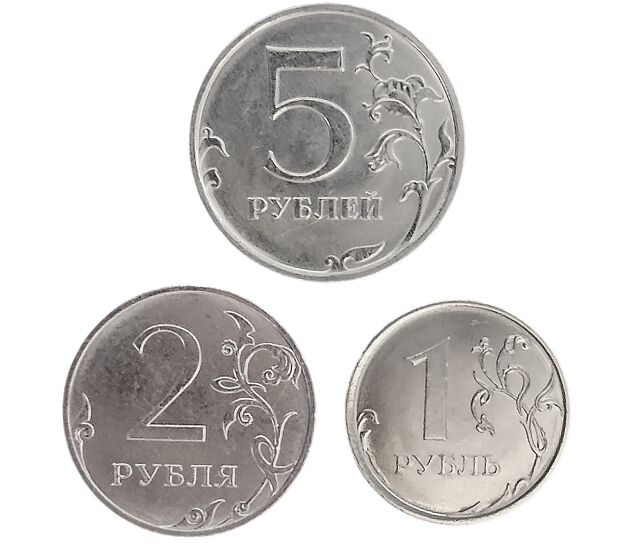

Оттенки серого


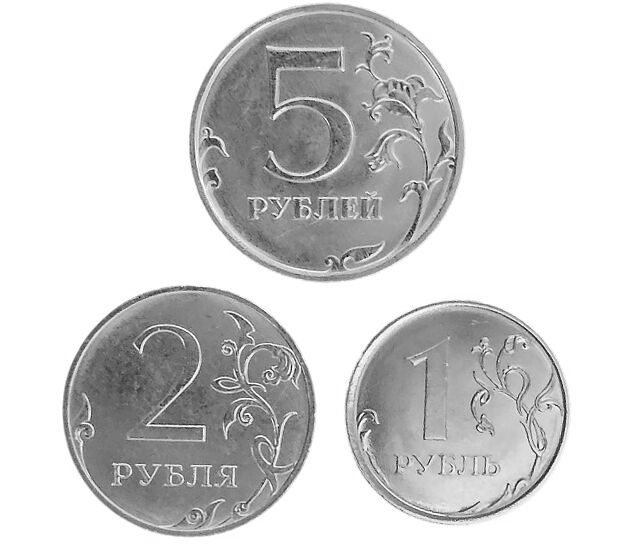

Размытие Гаусса


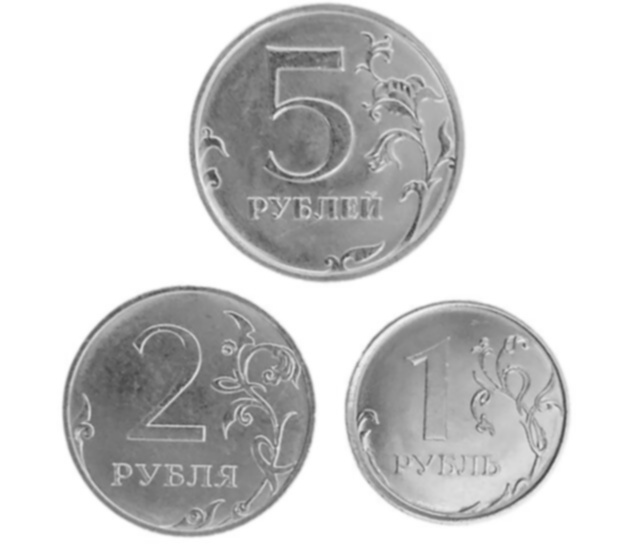

Границы Кэнни


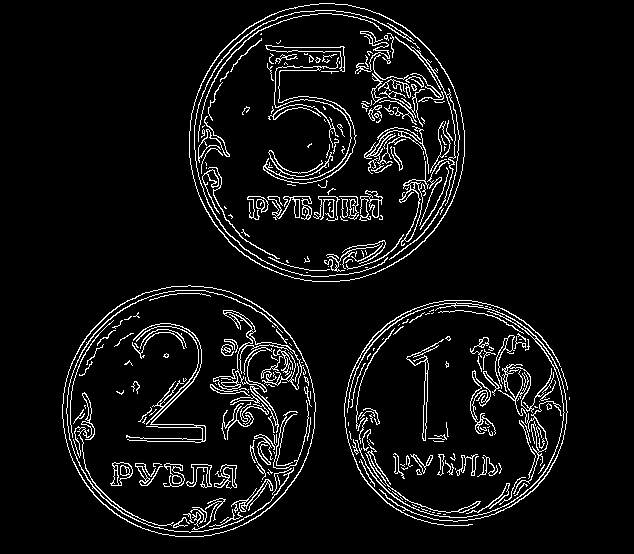

Найденные монеты


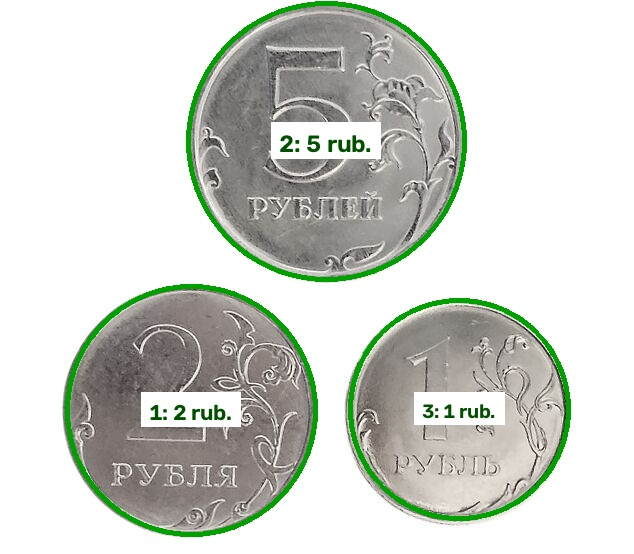

Монета 1: 2 руб., радиус 124 пкс
Монета 2: 5 руб., радиус 138 пкс
Монета 3: 1 руб., радиус 109 пкс
Найдено монет: 3
Общая сумма: 8 руб.


In [4]:
image_1 = load_image('https://filtorg.ru/images/thumbnails/634/554/detailed/87/20250506_101409-Photoroom.png')
coins_1 = count_coins(image_1, *radius_limits_1)

### Изображение 2

Исходное изображение


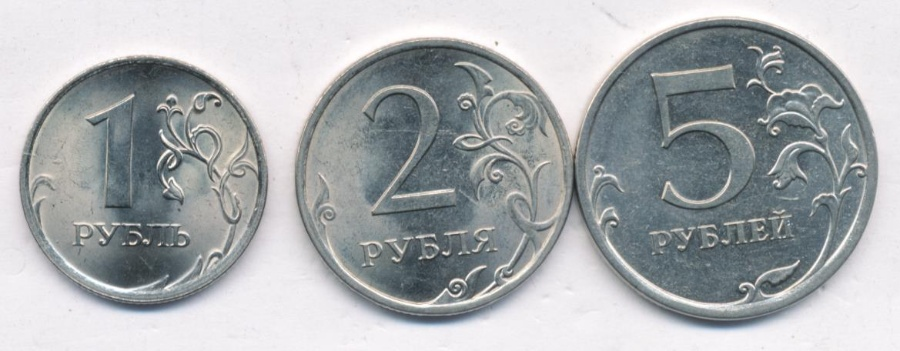

Оттенки серого


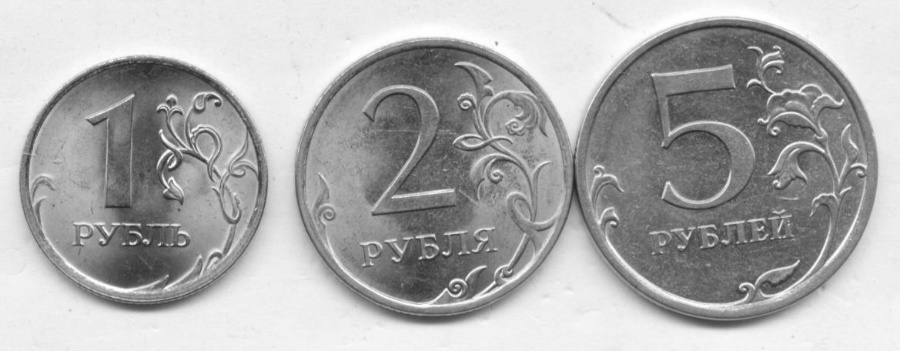

Размытие Гаусса


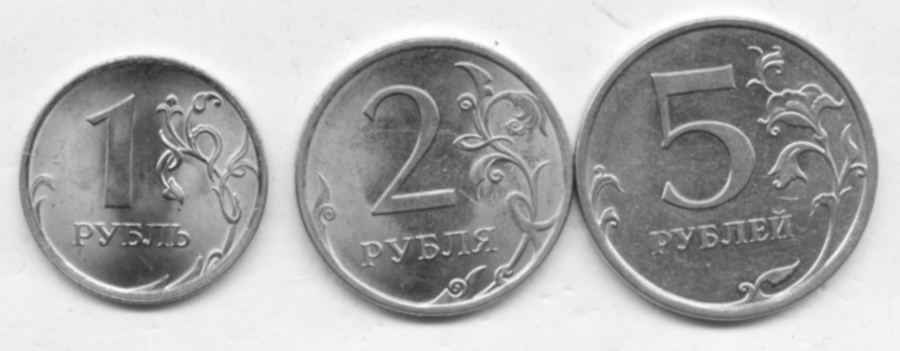

Границы Кэнни


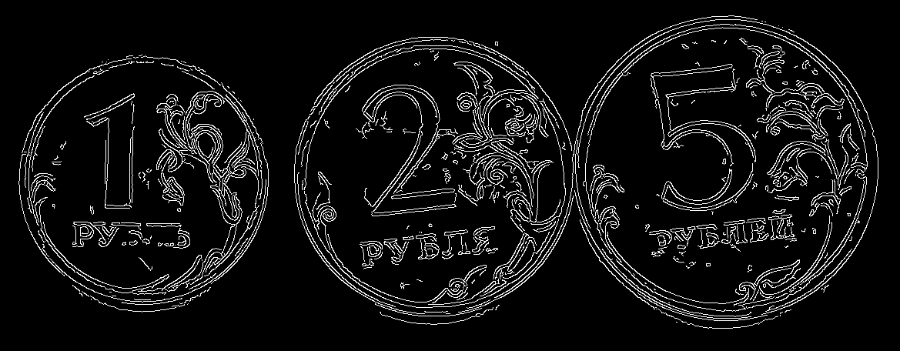

Найденные монеты


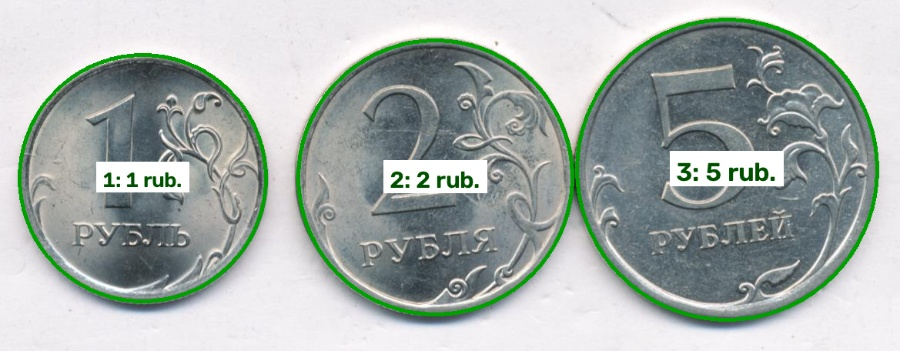

Монета 1: 1 руб., радиус 160 пкс
Монета 2: 2 руб., радиус 178 пкс
Монета 3: 5 руб., радиус 195 пкс
Найдено монет: 3
Общая сумма: 8 руб.


In [5]:
image_2 = load_image('https://auction.conros.ru/img/488/2255+.jpg')
coins_2 = count_coins(image_2, *radius_limits_2)

### Изображение 1: яркость 65%

Найденные монеты


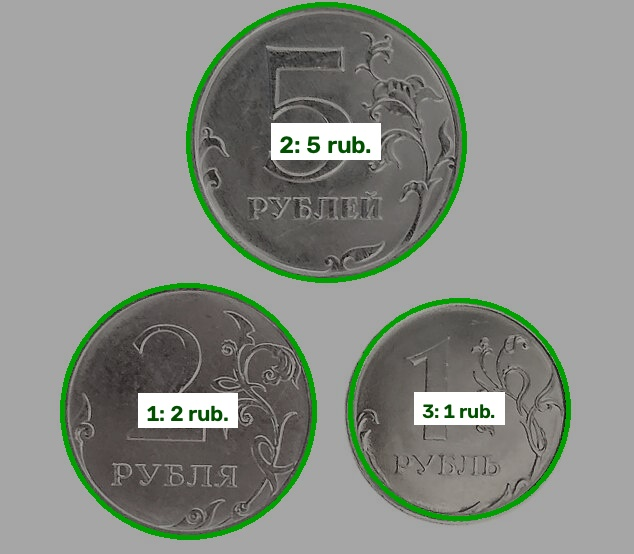

Монета 1: 2 руб., радиус 126 пкс
Монета 2: 5 руб., радиус 138 пкс
Монета 3: 1 руб., радиус 109 пкс
Найдено монет: 3
Общая сумма: 8 руб.


In [6]:
if image_1 is not None:
    darker = cv2.convertScaleAbs(image_1, alpha=0.65)
    coins_dark = count_coins(darker, *radius_limits_1, show_steps=False)

### Вывод

На обоих изображениях и при снижении яркости найдены все монеты. Сумма — по 8 рублей. Для другого масштаба нужно изменить пороги радиусов.